In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score



In [9]:


try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop("target", axis=1)
y = df["target"].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

feature_names = X.columns.tolist()



In [10]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



In [11]:

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

test_predictions = model.predict(X_test)

print("Original Model Accuracy:",
      round(accuracy_score(y_test, test_predictions), 4))

print("Original Model F1 Score:",
      round(f1_score(y_test, test_predictions), 4))




Original Model Accuracy: 0.7705
Original Model F1 Score: 0.7879


In [12]:


class_index = list(model.classes_).index(1)

def original_model_predict(data):

    probabilities = model.predict_proba(data)

    return probabilities[:, class_index]




In [13]:


def generate_perturbed_data(
    observation,
    number_of_samples=3000,
    noise_level=0.5,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    number_of_features = len(observation)

    perturbations = rng.normal(
        loc=observation,
        scale=noise_level,
        size=(number_of_samples, number_of_features)
    )

    perturbations[0] = observation

    return perturbations




In [14]:


def calculate_sample_weights(
    perturbations,
    observation,
    kernel_width=0.75
):

    distances = np.sqrt(
        np.mean(
            (perturbations - observation) ** 2,
            axis=1
        )
    )

    weights = np.exp(
        -(distances ** 2) / (kernel_width ** 2)
    )

    return weights




In [15]:


def train_surrogate_model(
    X_local,
    y_local,
    sample_weights,
    regularization=0.01
):

    number_of_samples, number_of_features = X_local.shape

    X_design = np.column_stack([
        np.ones(number_of_samples),
        X_local
    ])

    weight_matrix = np.diag(sample_weights)

    identity = np.eye(number_of_features + 1)

    identity[0, 0] = 0

    coefficients = np.linalg.solve(
        X_design.T @ weight_matrix @ X_design
        + regularization * identity,

        X_design.T @ weight_matrix @ y_local
    )

    intercept = coefficients[0]
    feature_coefficients = coefficients[1:]

    return intercept, feature_coefficients








In [16]:


def surrogate_predict(
    X_local,
    intercept,
    coefficients
):

    predictions = (
        intercept + X_local @ coefficients
    )

    return np.clip(predictions, 0, 1)


In [17]:


def calculate_weighted_r2(
    actual,
    predicted,
    weights
):

    weighted_mean = np.average(
        actual,
        weights=weights
    )

    residual_sum = np.sum(
        weights * (actual - predicted) ** 2
    )

    total_sum = np.sum(
        weights * (actual - weighted_mean) ** 2
    )

    if total_sum < 1e-12:
        return np.nan

    return 1 - residual_sum / total_sum


def calculate_weighted_mae(
    actual,
    predicted,
    weights
):

    return np.average(
        np.abs(actual - predicted),
        weights=weights
    )


In [18]:


def explain_prediction(
    observation,
    observation_number,
    number_of_samples=3000,
    random_state=42
):

    perturbed_data = generate_perturbed_data(
        observation,
        number_of_samples=number_of_samples,
        random_state=random_state
    )

    original_predictions = original_model_predict(
        perturbed_data
    )

    sample_weights = calculate_sample_weights(
        perturbed_data,
        observation
    )

    local_features = perturbed_data - observation

    rng = np.random.default_rng(random_state)

    indices = rng.permutation(len(perturbed_data))

    split_point = int(0.70 * len(indices))

    train_indices = indices[:split_point]
    validation_indices = indices[split_point:]

    X_local_train = local_features[train_indices]

    y_local_train = original_predictions[train_indices]
    weights_train = sample_weights[train_indices]

    X_local_validation = local_features[validation_indices]
    y_local_validation = original_predictions[validation_indices]
    weights_validation = sample_weights[validation_indices]

    intercept, coefficients = train_surrogate_model(
        X_local_train,
        y_local_train,
        weights_train
    )

    surrogate_predictions = surrogate_predict(
        X_local_validation,
        intercept,
        coefficients
    )

    weighted_r2 = calculate_weighted_r2(
        y_local_validation,
        surrogate_predictions,
        weights_validation
    )

    weighted_mae = calculate_weighted_mae(
        y_local_validation,
        surrogate_predictions,
        weights_validation
    )

    original_prediction = original_model_predict(
        observation.reshape(1, -1)
    )[0]

    surrogate_prediction = float(intercept)

    prediction_difference = abs(
        original_prediction - surrogate_prediction
    )

   
    feature_effects = coefficients.copy()

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "Local Coefficient": feature_effects,
        "Absolute Contribution": np.abs(feature_effects)
    })

    explanation = explanation.sort_values(
        "Absolute Contribution",
        ascending=False
    ).reset_index(drop=True)

    validation_results = {
        "Observation": observation_number,
        "Original Probability": original_prediction,
        "Surrogate Probability": surrogate_prediction,
        "Prediction Difference": prediction_difference,
        "Validation Weighted R2": weighted_r2,
        "Validation Weighted MAE": weighted_mae
    }

    return explanation, validation_results




In [19]:


number_of_observations = min(10, len(X_test))

all_explanations = []
validation_results = []

for i in range(number_of_observations):

    explanation, validation = explain_prediction(
        observation=X_test[i],
        observation_number=i + 1,
        number_of_samples=3000,
        random_state=42 + i
    )

    all_explanations.append(explanation)
    validation_results.append(validation)

    print("\nObservation:", i + 1)

    print(
        explanation.head(10).round(4).to_string(index=False)
    )

    print(
        "Original Probability:",
        round(validation["Original Probability"], 4)
    )

    print(
        "Surrogate Probability:",
        round(validation["Surrogate Probability"], 4)
    )

    print(
        "Validation Weighted R2:",
        round(validation["Validation Weighted R2"], 4)
    )

    print(
        "Validation Weighted MAE:",
        round(validation["Validation Weighted MAE"], 4)
    )





Observation: 1
 Feature  Local Coefficient  Absolute Contribution
      cp             0.1642                 0.1642
 thalach             0.1347                 0.1347
 oldpeak            -0.0501                 0.0501
      ca            -0.0466                 0.0466
    thal            -0.0307                 0.0307
trestbps            -0.0223                 0.0223
   slope             0.0187                 0.0187
     age             0.0153                 0.0153
   exang            -0.0082                 0.0082
     sex             0.0052                 0.0052
Original Probability: 0.15
Surrogate Probability: 0.2222
Validation Weighted R2: 0.4898
Validation Weighted MAE: 0.0833

Observation: 2
 Feature  Local Coefficient  Absolute Contribution
      ca            -0.1224                 0.1224
 thalach             0.0610                 0.0610
    chol            -0.0401                 0.0401
     age            -0.0207                 0.0207
     sex            -0.0150     

In [20]:


validation_df = pd.DataFrame(validation_results)

print("\nINDEPENDENT LIME VALIDATION")
print(validation_df.round(4).to_string(index=False))

validation_df.to_csv(
    "manual_lime_validation.csv",
    index=False
)





INDEPENDENT LIME VALIDATION
 Observation  Original Probability  Surrogate Probability  Prediction Difference  Validation Weighted R2  Validation Weighted MAE
           1                0.1500                 0.2222                 0.0722                  0.4898                   0.0833
           2                0.6796                 0.6820                 0.0024                  0.3088                   0.0743
           3                0.0450                 0.0792                 0.0342                  0.4475                   0.0449
           4                0.7617                 0.6758                 0.0859                  0.5398                   0.0694
           5                0.8939                 0.8101                 0.0838                  0.2738                   0.0735
           6                0.0500                 0.1261                 0.0761                  0.4876                   0.0586
           7                0.8581                 0.7988    

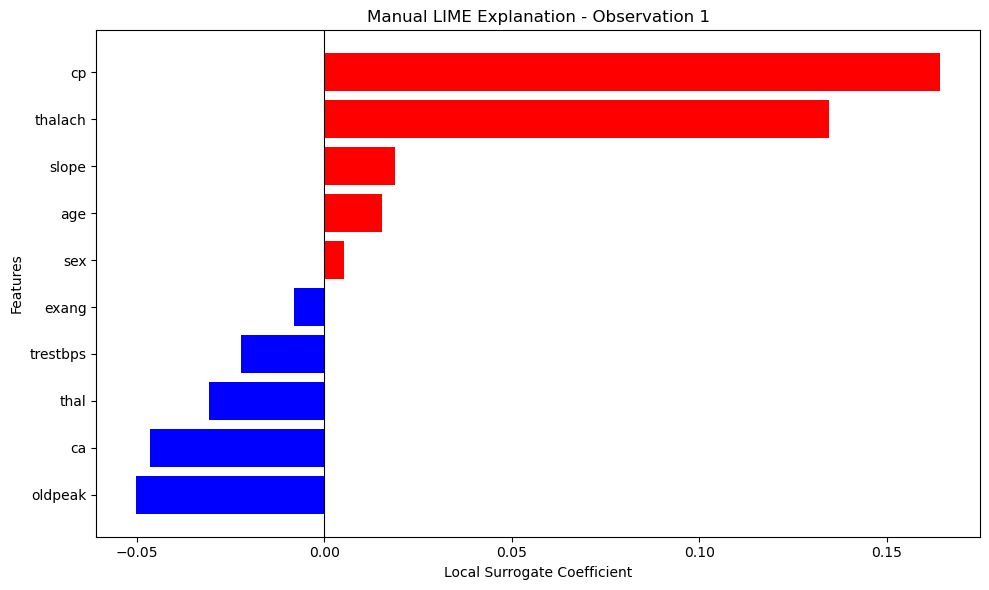

In [21]:


observation_to_plot = 0

selected_explanation = all_explanations[
    observation_to_plot
].head(10).sort_values(
    "Local Coefficient"
)

plt.figure(figsize=(10, 6))

colors = [
    "red" if value > 0 else "blue"
    for value in selected_explanation["Local Coefficient"]
]

plt.barh(
    selected_explanation["Feature"],
    selected_explanation["Local Coefficient"],
    color=colors
)

plt.axvline(
    0,
    color="black",
    linewidth=0.8
)

plt.xlabel("Local Surrogate Coefficient")
plt.ylabel("Features")

plt.title(
    f"Manual LIME Explanation - Observation "
    f"{observation_to_plot + 1}"
)

plt.tight_layout()
plt.show()




In [22]:


all_coefficients = np.array([
    explanation.set_index("Feature")
    .reindex(feature_names)["Local Coefficient"].values
    for explanation in all_explanations
])

variability_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute Contribution": np.mean(
        np.abs(all_coefficients),
        axis=0
    ),
    "Mean Coefficient": np.mean(
        all_coefficients,
        axis=0
    ),
    "Contribution Standard Deviation": np.std(
        all_coefficients,
        axis=0
    )
})

variability_df = variability_df.sort_values(
    "Mean Absolute Contribution",
    ascending=False
).reset_index(drop=True)

print("\nLIME FEATURE VARIABILITY")
print(variability_df.round(4).to_string(index=False))

variability_df.to_csv(
    "manual_lime_feature_variability.csv",
    index=False
)





LIME FEATURE VARIABILITY
 Feature  Mean Absolute Contribution  Mean Coefficient  Contribution Standard Deviation
      ca                      0.0666           -0.0664                           0.0457
 thalach                      0.0582            0.0575                           0.0443
      cp                      0.0556            0.0551                           0.0521
 oldpeak                      0.0283           -0.0278                           0.0228
     age                      0.0252            0.0114                           0.0256
    chol                      0.0224           -0.0154                           0.0244
    thal                      0.0191           -0.0176                           0.0153
trestbps                      0.0176           -0.0027                           0.0218
     sex                      0.0069           -0.0059                           0.0052
   exang                      0.0050           -0.0034                           0.0052
   slo

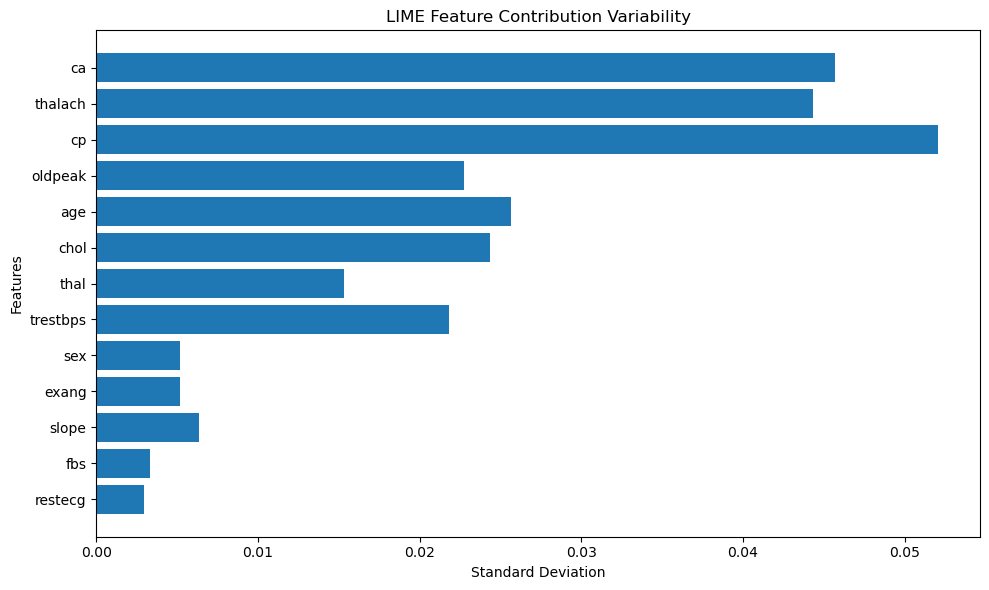

In [23]:


plt.figure(figsize=(10, 6))

plt.barh(
    variability_df["Feature"],
    variability_df["Contribution Standard Deviation"]
)

plt.gca().invert_yaxis()

plt.xlabel("Standard Deviation")
plt.ylabel("Features")

plt.title("LIME Feature Contribution Variability")

plt.tight_layout()
plt.show()




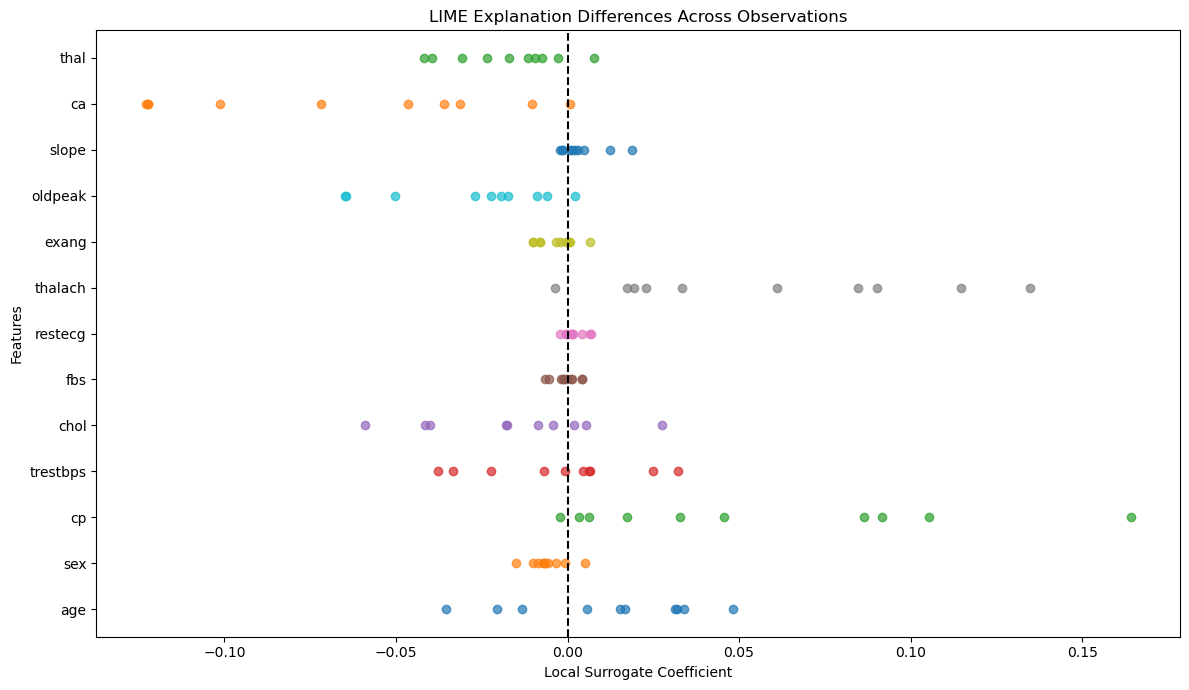

In [24]:


plt.figure(figsize=(12, 7))

for feature_index, feature in enumerate(feature_names):

    values = all_coefficients[:, feature_index]

    plt.scatter(
        values,
        np.full(len(values), feature_index),
        alpha=0.7
    )

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.yticks(
    range(len(feature_names)),
    feature_names
)

plt.xlabel("Local Surrogate Coefficient")
plt.ylabel("Features")

plt.title("LIME Explanation Differences Across Observations")

plt.tight_layout()
plt.show()




In [25]:


print("\nFINAL LIME ANALYSIS")
print("----------------------------")

print(
    "Average Validation Weighted R2:",
    round(
        validation_df["Validation Weighted R2"].mean(),
        4
    )
)

print(
    "Average Validation Weighted MAE:",
    round(
        validation_df["Validation Weighted MAE"].mean(),
        4
    )
)

print(
    "Average Prediction Difference:",
    round(
        validation_df["Prediction Difference"].mean(),
        4
    )
)

print(
    "\nMost Influential Feature:",
    variability_df.iloc[0]["Feature"]
)

print(
    "Most Variable Feature:",
    variability_df.loc[
        variability_df[
            "Contribution Standard Deviation"
        ].idxmax(),
        "Feature"
    ]
)

print("\nManual LIME implementation completed.")



FINAL LIME ANALYSIS
----------------------------
Average Validation Weighted R2: 0.42
Average Validation Weighted MAE: 0.0603
Average Prediction Difference: 0.054

Most Influential Feature: ca
Most Variable Feature: cp

Manual LIME implementation completed.
